# Validated GenAI Analysis of Public Comments on the FTC's Personalized-Pricing Policy

## 1. Business understanding

**Context.** In August 2026 the Federal Trade Commission (FTC) proposed an enforcement policy on *personalized pricing*: businesses using a consumer's personal data to estimate what that person will pay, and setting their price accordingly. The proposal does not ban the practice. It says businesses may break the law if they fail to clearly disclose that a price is personalized, why, and what data was used. The public comment period (docket FTC-2026-1057) closed on September 25, 2026, with 3,706 public comments.

**The business problem.** Regulators, law firms and public-affairs teams must read and summarize thousands of comments like these by hand. GenAI could do this faster and more cheaply, but a misread comment misrepresents the public record. Before anyone relies on it, the AI's accuracy has to be measured against careful human judgment.

**Research questions.**

*Workflow (for organizations adopting GenAI):*
1. How accurately does an LLM classify comments compared with human coders?
2. What does it cost per comment compared with human analysts?
3. Where does it fail?
4. What controls make it safe to use?

*Findings (for companies that use personalized pricing):*

5. What do individual commenters object to: the price difference, the use of their data, or the lack of disclosure?
6. What do they want the FTC to do?

**Scope.** This study analyzes comments from **individuals**. Submissions from organizations (companies, trade groups, advocacy groups) are mostly long attached documents that need a different method; comparing them with individuals is left for future work.

**Approach.** Understand → Use → Evaluate → Govern. Findings are reported only for labels the AI has been shown to classify reliably.

## Setup

In [5]:
# Loads the libraries and defines the settings and file paths
# used in the rest of the notebook. Every setting that affects
# results is defined here, so it only needs changing in one place.

# Standard library
import os                      # environment variables (e.g., the API key)
import re                      # regular expressions, for cleaning text
import html                    # decodes HTML codes such as &rsquo; into normal characters
import json                    # reads and writes the LLM's structured (JSON) output
from pathlib import Path       # builds file paths that work on Windows and Mac

# Data analysis and plotting
import numpy as np             # numerical operations
import pandas as pd            # loading and manipulating the comment data
import matplotlib.pyplot as plt  # charts
import seaborn as sns          # nicer charts

# Machine learning and text analysis
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import NMF
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# LLM (Claude) settings
import time
from dotenv import load_dotenv
import anthropic

# Reproducibility settings
# The same random seed was used to draw the comment sample from the API,
# so anyone rerunning the notebook gets exactly the same results.
SEED = 20261027

# Total public comments on docket FTC-2026-1057, as reported by the
# Regulations.gov API. Used to describe how much of the docket we analyze.
DOCKET_TOTAL = 3706

# File paths
# The notebook lives in Notebooks/, but the data is at the top of the repo.
# Find the repo's top folder by walking up until we find the Data folder,
# so the paths work no matter where the notebook is run from.
ROOT = Path.cwd()
while not (ROOT / "Data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Input: individual comments pulled from the Regulations.gov API.
DATA_FILE = ROOT / "Data" / "Used_individuals_sentiment_data.csv"

# Output: folder for saved charts, at the top of the repo; created if needed.
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Display settings
# Show up to 120 characters of each comment when printing tables.
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

# Check the input file exists before going further
# Stops the notebook with a clear message if the file is missing or misnamed,
# instead of failing later with a confusing error.
assert DATA_FILE.exists(), f"Missing {DATA_FILE}: check the folder and file name"
print("Setup complete. Data file found:", DATA_FILE)

Setup complete. Data file found: c:\Users\ADMIN\Documents\Daniels College of Business\Fall 2026\Analytics & AI\ftc-pricing-comments-genai\Data\Used_individuals_sentiment_data.csv


## 2. Data understanding

**Source.** Public comments on docket FTC-2026-1057, retrieved from the official Regulations.gov v4 API. All comment IDs on the docket were shuffled with a fixed seed (20261027) and fetched in that order, so the comments retrieved form a simple random sample of the docket.

**Unit of observation.** One public comment submitted by an individual.

**Privacy.** Commenters' names were excluded at download. Only the comment text, posting date and, where given, the U.S. state are kept.

In [6]:
# LOAD THE DATA AND TAKE A FIRST LOOK
# Before cleaning anything, check what the file contains:
# its size, its columns, their types and any missing values.

# Load the comments
df_raw = pd.read_csv(DATA_FILE)

# Size of the dataset
# Each row should be one comment.
print(f"Rows (comments): {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"Share of the full docket: {len(df_raw) / DOCKET_TOTAL:.1%} of {DOCKET_TOTAL:,} comments\n")

#  Columns and their data types
# Confirms each column was read as expected (text, numbers, dates).
print("Columns and types:")
print(df_raw.dtypes, "\n")

# Missing values per column
# Some missing values are expected (e.g., not every commenter gives a state).
print("Missing values per column:")
print(df_raw.isna().sum(), "\n")

# A few example rows
# Shows what the raw comment text looks like before cleaning.
df_raw.head()

Rows (comments): 1,566
Columns: 10
Share of the full docket: 42.3% of 3,706 comments

Columns and types:
comment_id           str
stratum              str
posted_date          str
organization     float64
state                str
withdrawn           bool
n_attachments      int64
comment_text         str
n_words            int64
shuffle_rank       int64
dtype: object 

Missing values per column:
comment_id          0
stratum             0
posted_date         0
organization     1566
state             554
withdrawn           0
n_attachments       0
comment_text        0
n_words             0
shuffle_rank        0
dtype: int64 



,comment_id,stratum,posted_date,organization,state,withdrawn,n_attachments,comment_text,n_words,shuffle_rank
0,FTC-2026-1057-0118,A_individual,2026-08-31T04:00:00Z,NaN,MA,False,0,"Dear Sir or Madam,\r\n\r\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether...",112,0
1,FTC-2026-1057-2221,A_individual,2026-09-24T04:00:00Z,NaN,FL,False,0,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual ...",17,1
2,FTC-2026-1057-2723,A_individual,2026-09-24T04:00:00Z,NaN,NaN,False,0,Absolutely preposterous idea to set prices based on personal information!!,10,2
3,FTC-2026-1057-1366,A_individual,2026-09-23T04:00:00Z,NaN,NaN,False,0,Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon...,22,3
4,FTC-2026-1057-3459,A_individual,2026-09-25T04:00:00Z,NaN,NaN,False,0,Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is delibera...,46,4


### what the data contains

- **1,566 individual comments**, 42.3% of the 3,706 comments on the docket. They were drawn in a fixed random order (seed 20261027), so they form a random sample of individual commenters.
- **10 columns**: a comment ID, the comment text, a word count, the posting date, the commenter's U.S. state, the position in the random order (`shuffle_rank`), and four columns describing the submission type (`stratum`, `organization`, `withdrawn`, `n_attachments`).
- **Missing values are expected, not errors.** `organization` is empty for every row because these are individuals. `state` is missing for 554 comments (35%) because giving a state is optional on Regulations.gov.
- **No missing comment text, IDs or dates**, so every row can be analyzed.
- The four submission-type columns should be the same for every row (individual, no organization, not withdrawn, no attachments). We verify this in cleaning and then drop them.

## 3. Data cleaning

Each cleaning step is checked with an `assert`, so the notebook stops with a clear message if the data is not what we expect.

In [7]:
# Turns the raw file into an analysis-ready table and checks
# every assumption we rely on later.

df = df_raw.copy()   # keep the raw data untouched for reference

# 1. Confirm every row is an individual comment
# These columns describe submission type. For individuals they should
# be identical on every row; if so, they carry no information.
assert (df["stratum"] == "A_individual").all(), "Non-individual rows found"
assert df["organization"].isna().all(), "Some rows name an organization"
assert (~df["withdrawn"]).all(), "Some comments were withdrawn"
assert (df["n_attachments"] == 0).all(), "Some comments have attachments"
df = df.drop(columns=["stratum", "organization", "withdrawn", "n_attachments"])

# 2. Clean the comment text
# Regulations.gov stores comments as HTML. Turn line-break tags into
# real line breaks, remove any other tags, decode codes like &rsquo;
# into normal characters, and collapse repeated spaces.
def clean_text(t):
    t = str(t).replace("\r\n", "\n").replace("\r", "\n")   # normalize Windows line breaks
    t = re.sub(r"(?i)<br\s*/?>", "\n", t)
    t = re.sub(r"<[^>]+>", " ", t)
    t = html.unescape(t)
    t = re.sub(r"\n{3,}", "\n\n", t)                          # at most one blank line in a row
    return re.sub(r"[ \t]+", " ", t).strip()

df["text"] = df["comment_text"].map(clean_text)
df = df.drop(columns=["comment_text"])

# 3. Recount words on the cleaned text
df["n_words"] = df["text"].str.split().str.len()

# 4. Convert the posting date from text to a real date
df["posted_date"] = pd.to_datetime(df["posted_date"]).dt.date

# 5. Flag (do not delete) very short comments
# Comments under 5 words often carry little meaning ("Stop this.").
# We keep them but flag them, so later steps can report their effect.
df["is_short"] = df["n_words"] < 5

# 6. Checks on the cleaned data
assert df["comment_id"].is_unique, "Duplicate comment IDs"
assert df["comment_id"].str.match(r"^FTC-2026-1057-\d{4}$").all(), "Unexpected ID format"
assert (df["text"].str.len() > 0).all(), "Empty comment text after cleaning"
assert not df["text"].str.contains(r"&[a-z]+;|<br", regex=True).any(), "HTML left in text"
assert not any(c in df.columns for c in ["first_name", "last_name", "firstName", "lastName"]), \
    "Personal names present (privacy rule)"

# 7. Sampling check
# Comments were fetched in a fixed random order (seed 20261027), and
# shuffle_rank records each comment's position in that order. Each
# position should appear once and fall within the docket's range.
assert df["shuffle_rank"].is_unique, "Two comments share a position in the random order"
assert df["shuffle_rank"].between(0, DOCKET_TOTAL - 1).all(), "Position outside the docket's range"

print(f"Clean dataset: {len(df):,} comments, columns: {list(df.columns)}")
print(f"Very short comments (<5 words): {df['is_short'].sum()} ({df['is_short'].mean():.1%})")
df.head()

Clean dataset: 1,566 comments, columns: ['comment_id', 'posted_date', 'state', 'n_words', 'shuffle_rank', 'text', 'is_short']
Very short comments (<5 words): 56 (3.6%)


,comment_id,posted_date,state,n_words,shuffle_rank,text,is_short
0,FTC-2026-1057-0118,2026-08-31,MA,112,0,"Dear Sir or Madam,\n\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether. It...",False
1,FTC-2026-1057-2221,2026-09-24,FL,17,1,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual ...",False
2,FTC-2026-1057-2723,2026-09-24,NaN,10,2,Absolutely preposterous idea to set prices based on personal information!!,False
3,FTC-2026-1057-1366,2026-09-23,NaN,22,3,Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon...,False
4,FTC-2026-1057-3459,2026-09-25,NaN,46,4,Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is delibera...,False


## 4. Summary statistics

In [8]:
# SUMMARY STATISTICS
# Describes the cleaned comments: how long they are, when they
# were posted and where commenters are from.

# Comment length
# Mean and median words, plus spread. A mean far above the median
# signals a few very long comments pulling the average up.
length = df["n_words"].describe(percentiles=[.25, .5, .75, .9]).round(1)
print("Words per comment:")
print(length.to_string(), "\n")

# Posting dates
print(f"Posted between {df['posted_date'].min()} and {df['posted_date'].max()}")
by_date = df.groupby("posted_date").size()
top3 = by_date.nlargest(3)
print(f"Busiest days: " + ", ".join(f"{d} ({n})" for d, n in top3.items()))
print(f"Share posted on the 3 busiest days: {top3.sum() / len(df):.0%}\n")

# Commenter location (optional field)
print(f"State given: {df['state'].notna().mean():.0%} of comments")
print("Top 5 states:", df["state"].value_counts().head(5).to_dict())

# Charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. Length distribution. Clipped at 300 words so the long tail of
#    a few very long comments does not squash the main shape.
sns.histplot(df["n_words"].clip(upper=300), bins=40, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["n_words"].median(), color="black", ls="--", lw=1)
axes[0].set(title="Comment length (clipped at 300 words)", xlabel="Words", ylabel="Comments")
axes[0].text(df["n_words"].median() + 5, axes[0].get_ylim()[1] * 0.9,
             f"median = {df['n_words'].median():.0f}", fontsize=9)

# 2. Comments per posting date
sns.lineplot(x=pd.to_datetime(by_date.index), y=by_date.values, marker="o", ax=axes[1], color="#4C72B0")
axes[1].set(title="Comments by posting date", xlabel="", ylabel="Comments")
axes[1].tick_params(axis="x", rotation=45)

# 3. Top 10 states
top_states = df["state"].value_counts().head(10)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[2], color="#4C72B0")
axes[2].set(title="Top 10 states (where given)", xlabel="Comments", ylabel="")

plt.tight_layout()
plt.savefig(FIG / "summary_statistics.png", dpi=150, bbox_inches="tight")
plt.show()

Words per comment:
count    1566.0
mean       56.5
std        91.1
min         1.0
25%        14.0
50%        28.0
75%        59.0
90%       119.0
max       820.0 

Posted between 2026-08-19 and 2026-09-28
Busiest days: 2026-09-24 (463), 2026-09-23 (378), 2026-08-31 (349)
Share posted on the 3 busiest days: 76%

State given: 65% of comments
Top 5 states: {'CA': 143, 'NY': 63, 'FL': 61, 'TX': 56, 'WA': 52}


<Figure size 1600x420 with 3 Axes>

### What the summary statistics show

- **Comments are short and review-like.** The median comment is 28 words; half are between 14 and 59 words, and 90% are under 120 words. A small number of long comments (up to 820 words) pull the mean up to 56.5 words, so the median is the better summary. The bar at 300 in the chart gathers all comments over 300 words.
- **Short comments suit the classification task.** Most comments state one position in a few sentences, which should make them easier to label consistently, for humans and for the LLM. The 56 comments under 5 words (3.6%) are flagged in case they carry too little information.
- **Posting is concentrated on three days.** Comments were posted between August 19 (the day the proposal was published) and September 28. 76% were posted on just three days: September 24 (463), September 23 (378) and August 31 (349). `posted_date` records when the FTC published a comment online, not when it was submitted, so these spikes most likely reflect batch posting by the agency; organized campaigns may also contribute, which we check with near-duplicate detection next.
- **Commenters come from across the country.** 65% give a U.S. state. California leads (143), followed by New York (63), Florida (61), Texas (56) and Washington (52), broadly in line with state populations.
- **Commenters are self-selected.** People choose whether to comment, so these results describe *commenters*, not the U.S. public. All findings are worded accordingly.

## 5. Form letters (near-duplicate comments)

In [9]:
# NEAR-DUPLICATE (FORM-LETTER) DETECTION
# Organized campaigns can submit many near-identical comments,
# which would inflate one position in the results. We flag them
# (not delete them) and later report findings with and without them.

DUP_THRESHOLD = 0.80   # two comments this similar or more count as near-duplicates

# 1. Turn each comment into a word-weight vector (TF-IDF) ---
# Common English words are ignored; word pairs (bigrams) capture phrasing.
X = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit_transform(df["text"])

# 2. Compare every comment with every other (cosine similarity, 0 to 1) ---
sim = cosine_similarity(X)
np.fill_diagonal(sim, 0)          # ignore each comment's similarity to itself

#  3. Group comments linked by high similarity
# If A ~ B and B ~ C, all three join one group (one "form letter").
_, groups = connected_components(csr_matrix(sim >= DUP_THRESHOLD), directed=False)
df["dup_group"] = groups
df["dup_group_size"] = df.groupby("dup_group")["comment_id"].transform("size")
df["is_near_duplicate"] = df["dup_group_size"] > 1

# Keep one comment per group as its representative, for the sensitivity check later.
df["is_group_representative"] = ~df.duplicated("dup_group")

# 4. Report
n_dup = df["is_near_duplicate"].sum()
n_groups = df.loc[df["is_near_duplicate"], "dup_group"].nunique()
print(f"Near-duplicates: {n_dup} comments ({n_dup / len(df):.1%}) in {n_groups} groups")
print(f"Comments after keeping one per group: {df['is_group_representative'].sum():,}\n")

print("Largest groups (one example each):")
largest = (df[df["dup_group_size"] >= 3]
           .drop_duplicates("dup_group")
           .sort_values("dup_group_size", ascending=False)
           .head(5))
for _, r in largest.iterrows():
    print(f"  {r['dup_group_size']} comments | {r['text'][:110]!r}")

Near-duplicates: 59 comments (3.8%) in 22 groups
Comments after keeping one per group: 1,529

Largest groups (one example each):
  5 comments | 'No more surveillance pricing!!!'
  4 comments | 'This is not fair!!!'
  4 comments | 'Please stop personalized pricing NOW'
  4 comments | 'One price for everyone!'
  4 comments | 'From groceries to gas, the cost of necessities is continuing to skyrocket. During this time of economic stress'


### What do we find from Form letters detection?

- **59 comments (3.8%) are near-duplicates**, in 22 groups (TF-IDF cosine similarity ≥ 0.80). Keeping one comment per group leaves 1,529.
- **Most groups are short slogans**, such as "No more surveillance pricing!!!" (5 comments) and "One price for everyone!" (4). Identical short phrases can be written independently, so these are not necessarily coordinated.
- **One group is a campaign template**: "From groceries to gas, the cost of necessities is continuing to skyrocket…" (4 comments).
- **Implication.** Coordinated campaigns are a small share of this sample, so they are unlikely to drive the results. As a sensitivity check, key findings are also reported using one comment per group. The posting-date spikes in Section 4 are therefore not mainly form letters, consistent with batch posting by the agency.

## 6. Exploratory NLP. Topic modelling (what themes appear on their own?)

Before designing the labels the LLM will assign, we look at the comments bottom-up with two classic methods: **topic modelling**, to see which themes emerge without being told what to look for, and **sentiment analysis**, as a baseline to test whether tone can stand in for a commenter's position.

In [10]:
# TOPIC MODELLING (NMF on TF-IDF)
# Finds groups of words that tend to appear together. Each group
# is a "topic". Used to check that our label categories (codebook)
# cover the themes commenters actually raise.
K_TOPICS = 8   # number of topics; 8 gave distinct, readable themes

# 1. Word weights for each comment
# min_df=5: ignore words used in fewer than 5 comments (too rare to form a theme)
# max_df=0.6: ignore words in over 60% of comments (too common to separate themes)
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_df=0.6)
X_topics = vec.fit_transform(df["text"])
terms = np.array(vec.get_feature_names_out())

# 2. Fit the topic model
# NMF splits the comment-word matrix into topics. random_state fixes the result.
nmf = NMF(n_components=K_TOPICS, random_state=SEED, init="nndsvda", max_iter=500)
weights = nmf.fit_transform(X_topics)

# 3. Assign each comment its strongest topic
df["topic"] = weights.argmax(axis=1)

# 4. Show each topic's top words and size
for k, comp in enumerate(nmf.components_):
    top_words = ", ".join(terms[comp.argsort()[::-1][:8]])
    n = (df["topic"] == k).sum()
    print(f"Topic {k} ({n} comments, {n / len(df):.0%}): {top_words}")

Topic 0 (164 comments, 10%): personal, data, personal data, use, companies, using, information, use personal
Topic 1 (215 comments, 14%): surveillance pricing, surveillance, pricing, ban, ban surveillance, unfair, ftc, pricing unfair
Topic 2 (254 comments, 16%): personalized, personalized pricing, pricing, stop personalized, allow, unfair, consumer, illegal
Topic 3 (188 comments, 12%): price, price gouging, gouging, price price, item, price item, pay, consumers
Topic 4 (98 comments, 6%): stop, stop personalized, stop surveillance, needs, practice, pricing stop, invasion, unfair
Topic 5 (73 comments, 5%): commission, consumers, urge, ftc, disclose, companies disclose, merely, authority
Topic 6 (384 comments, 25%): people, just, money, corporations, pay, way, make, don
Topic 7 (190 comments, 12%): different, prices, fair, different prices, based, charge, charge different, product


### Insights

An 8-topic NMF model groups the comments into themes that match the coding dictionary's categories:

- **Privacy and data use**: Topic 0, "personal data" (10%).
- **Calls for a ban**: Topic 1, "ban surveillance pricing" (14%); Topic 2, "stop / illegal" (16%); Topic 4, short "stop it" demands (6%); and Topic 5, a campaign-style argument that disclosure is not enough and the FTC should use its full authority (5%).
- **Prices, gouging and corporations**: Topic 3, "price gouging" (12%), and Topic 6, general frustration about money and corporations (25%, the broadest topic).
- **Equal treatment**: Topic 7, "different prices for different people" (12%).

**What topics can and cannot tell us.** Topics show *what* people talk about, not *what they want*: a comment can ask for a ban in many ways, and Topic 6 mixes several concerns. Topic modelling therefore informs the coding dictionary but cannot replace a classifier that reads each comment's position.

**Dictionary implication.** The themes line up with the dictionary's reason categories (privacy, pricing and equal treatment, fairness and consumer harm, transparency). No topic covers legal or business arguments, which are rare among individuals; the dictionary keeps those categories so that rare but policy-relevant arguments are not lost.

### Naming the topics and linking them to the coding dictionary

The topic model only outputs numbered word lists. This step does three things:

1. **Names each topic** in plain English from its top words, so the themes are readable in the report and slides.
2. **Maps each topic to the dictionary**: to the closest **reason** category, and to a **stance** (ban-related topics map to `stronger_action`, all others to `unclear`, because word patterns alone rarely reveal what a commenter wants).
3. **Charts the share of comments in each theme.**

The mapping turns topic modelling into a simple **baseline classifier**. In Section 8 we score it against the human gold standard, alongside Claude, to measure whether the LLM adds accuracy over a classic method.

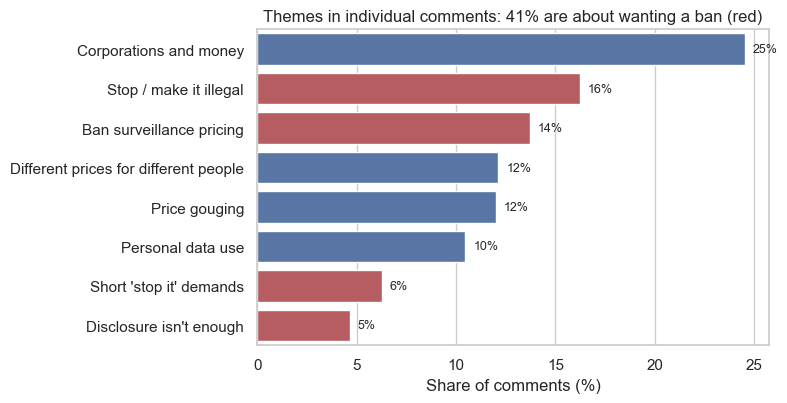

In [11]:
# Names make the topics readable in the report and slides. The
# mappings let us later test topic modelling as a simple baseline
# classifier against the human gold standard.

# 1. Plain-English names (based on each topic's top words)
TOPIC_NAMES = {
    0: "Personal data use",
    1: "Ban surveillance pricing",
    2: "Stop / make it illegal",
    3: "Price gouging",
    4: "Short 'stop it' demands",
    5: "Disclosure isn't enough",
    6: "Corporations and money",
    7: "Different prices for different people",
}

# 2. Map each topic to the closest reason category (None = the topic states a demand, not a reason)
TOPIC_TO_REASON = {
    0: "privacy_data_use",
    1: None,
    2: None,
    3: "pricing_affordability_equal_treatment",
    4: None,
    5: "transparency_disclosure",
    6: "fairness_discrimination_consumer_harm",
    7: "pricing_affordability_equal_treatment",
}
BAN_TOPIC_IDS = [1, 2, 4, 5]   # topics about wanting a ban -> stance stronger_action

df["topic_name"] = df["topic"].map(TOPIC_NAMES)
df["topic_reason"] = df["topic"].map(TOPIC_TO_REASON)                                   # baseline reason
df["topic_stance"] = np.where(df["topic"].isin(BAN_TOPIC_IDS), "stronger_action", "unclear")  # baseline stance
assert df["topic_name"].notna().all(), "Every comment must have a named topic"

# 3. Chart: share of comments per topic
# Largest theme on top; the four topics about wanting a ban are highlighted,
# because together they show how many commenters ask the FTC to go further.
BAN_TOPICS = {TOPIC_NAMES[k] for k in BAN_TOPIC_IDS}
topic_share = df["topic_name"].value_counts(normalize=True).sort_values(ascending=False) * 100
colors = ["#C44E52" if name in BAN_TOPICS else "#4C72B0" for name in topic_share.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(x=topic_share.values, y=topic_share.index, palette=colors, hue=topic_share.index,
            legend=False, ax=ax)
for i, v in enumerate(topic_share.values):
    ax.text(v + 0.4, i, f"{v:.0f}%", va="center", fontsize=9)
ban_total = topic_share[topic_share.index.isin(BAN_TOPICS)].sum()
ax.set(title=f"Themes in individual comments: {ban_total:.0f}% are about wanting a ban (red)",
       xlabel="Share of comments (%)", ylabel="")
plt.tight_layout()
plt.savefig(FIG / "topics.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this chart.** The topic model grouped words that tend to appear together into eight themes and placed each comment in the one theme it matches best. Each bar shows the **percentage of comments whose main theme** is that one; the bars add up to 100%.

- **Red bars** are themes where commenters **ask for the practice to be stopped or banned**: "Stop / make it illegal" (16%), "Ban surveillance pricing" (14%), short "stop it" demands (6%), and "Disclosure isn't enough" (5%). Together they cover **41% of comments**.
- **Blue bars** are themes about **why** commenters object: frustration with corporations and the cost of living (25%), unequal prices for the same product (12%), price gouging (12%), and the use of personal data (10%).

**Takeaway.** About four in ten commenters focus on demanding a ban; the rest mostly explain their objection through corporate behavior, unequal prices, or the use of their personal data.

**Caveat.** Topics are built from word patterns, not meaning, and each comment counts in only one theme even if it raises several. These shares are a first look; the validated estimates come from the LLM labels in Section 9.

## 7. Modelling

**Goal.** Label each comment with **what the commenter wants the FTC to do** (stance) and **the reasons they give** (one or more), accurately enough that the labels can be trusted for business findings.

**Approach.** We compare four models, from simplest to most capable:

1. **Sentiment baseline (VADER):** a free, dictionary-based tool that scores tone. Tests whether tone alone reveals what a commenter wants.
2. **Topic baseline:** each comment gets the stance and reason linked to its main topic (Section 6). Tests whether word patterns alone are enough.
3. **Supervised baseline (TF-IDF + logistic regression):** a classic text classifier trained on the human-labeled comments, scored by cross-validation. Tests what a traditional machine-learning approach achieves with the same labels.
4. **LLM classifier (Claude):** reads each comment and applies the coding dictionary, returning structured labels with a supporting quote.

**Why baselines.** An LLM costs money and adds risk. It is only worth using if it clearly beats cheaper methods, so every model is scored against the same human gold standard in Section 8.

### 7.1 Baseline 1: sentiment (VADER)

Sentiment analysis scores how positive or negative a text sounds. If tone could stand in for what a commenter wants, a simple, free sentiment tool would be enough and an LLM would be unnecessary. We test that here.

VADER sentiment labels:
vader_label
negative    55.9%
positive    32.1%
neutral     12.0%
Name: proportion, dtype: str 

Comments VADER rates most positive:
  - Public Comment Submission Docket ID: FTC-2026-1057  Re: Proposed Enforcement Policy Statement Regarding Personalized Pricing  Submitter: [NAME] / Concerned Consumer  I. The Best-Ca
  - I strongly support greater consumer protections against personalized pricing based on personal data.  Technology should make markets more competitive and transparent for consumers.
  - I am writing as both a consumer and a small-business attorney who regularly advises businesses regarding online transactions, disclosures, privacy, and consumer-facing practices. I
  - All prices should be the same for everybody, no matter how they look, how they dress, what brand is their car ,or i9f they have 2 $8,000 frenchies, or a street cat. This should be 
  - I strongly support the Federal Trade Commission taking a strong enforcement position against decept

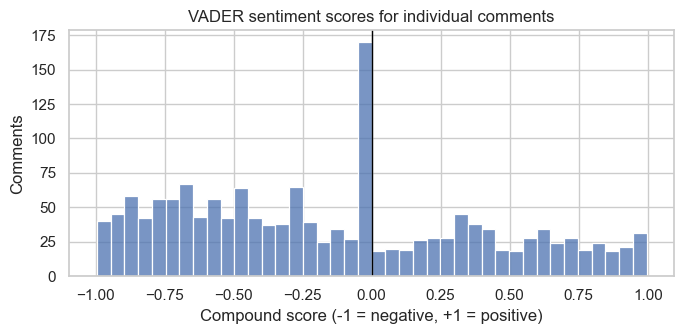

In [12]:
# VADER is a dictionary-based sentiment tool: it scores text from
# -1 (very negative) to +1 (very positive) by looking up words.
# We test whether tone matches what commenters actually think.

analyzer = SentimentIntensityAnalyzer()

# 1. Score each comment
# "compound" is VADER's overall score for the whole text.
df["vader_score"] = df["text"].map(lambda t: analyzer.polarity_scores(t)["compound"])

# 2. Convert scores to labels, using VADER's standard cut-offs
df["vader_label"] = pd.cut(df["vader_score"], bins=[-1.01, -0.05, 0.05, 1.01],
                           labels=["negative", "neutral", "positive"])

# 3. How are comments distributed?
print("VADER sentiment labels:")
print(df["vader_label"].value_counts(normalize=True).mul(100).round(1).astype(str) + "%", "\n")

# 4. Read the comments VADER rates most POSITIVE ---
# Some commenters type their own name into the text (e.g., "Submitter: ...").
# Mask common self-identification patterns before printing (privacy rule).
def mask_names(t):
    t = re.sub(r"(?i)(submitter|submitted by|name|sincerely|regards|respectfully)\s*[:,]?\s*[A-Z][\w.\-]*(\s+[A-Z][\w.\-]*){0,3}",
               r"\1: [NAME]", t)
    return t

print("Comments VADER rates most positive:")
for t in df.sort_values("vader_score", ascending=False)["text"].head(5):
    print("  -", mask_names(t).replace("\n", " ")[:180])

# 5. Chart
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df["vader_score"], bins=40, color="#4C72B0", ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set(title="VADER sentiment scores for individual comments",
       xlabel="Compound score (-1 = negative, +1 = positive)", ylabel="Comments")
plt.tight_layout()
plt.savefig(FIG / "vader_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this chart.** VADER gives each comment a score from −1 (very negative tone) to +1 (very positive tone). Each bar counts the comments with scores in that range; the black line marks a neutral score of 0.

**What it shows.** 56% of comments score negative, 32% positive and 12% neutral. The tall bar at 0 is mostly very short comments with no emotional words, such as "One price for everyone!".

**Why this matters: tone is not position.** Reading the comments VADER rates *most positive* shows they all oppose personalized pricing, for example: *"I strongly support greater consumer protections against personalized pricing based on personal data."* VADER scores words like "support", "protections" and "fair" as positive, even when they are used to demand stronger regulation. A third of commenters would be misread as positive if tone were used as a stand-in for their position.

**Takeaway.** A cheap sentiment tool cannot tell us what commenters want, which is why we need a classifier that reads each comment against defined categories. In Section 8 we measure this gap by scoring VADER against the human gold standard (negative tone → `stronger_action`, positive → `support_as_proposed`, neutral → `unclear`).

### 7.2 Baseline 2: topics as a classifier

The topic model from Section 6 can be used as a simple classifier: each comment gets the stance and reason linked to its main topic (columns `topic_stance` and `topic_reason`). It needs no labels and no API, so it is a natural low-cost baseline. Its weakness is already visible: ban-related topics say what commenters *want* but not *why*, and every other topic says *why* but not *what they want*. Section 8 scores this baseline against the gold standard.

### 7.3 Baseline 3: supervised classifier (TF-IDF + logistic regression)

A traditional classifier learns from labeled examples: it turns each comment into word and word-pair weights (TF-IDF, as in Section 5) and fits a logistic regression to predict the stance. It needs the human labels, so it is trained and scored on the gold set using **cross-validation**: the gold comments are split into folds, and each fold is predicted by a model trained on the others, so no comment is scored by a model that saw it. Class weights are balanced so rare stances are not ignored. It is defined here and run in Section 8.

In [13]:
# SUPERVISED BASELINE: TF-IDF + LOGISTIC REGRESSION
# Defined here, trained and scored in Section 8 once human labels exist.
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict

def tfidf_logreg_cv(texts, labels, n_folds=5):
    """Cross-validated stance predictions: each comment is predicted by a model that never saw it."""
    model = make_pipeline(
        TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    )
    folds = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    return cross_val_predict(model, texts, labels, cv=folds)

print("Supervised baseline defined (runs in Section 8).")

Supervised baseline defined (runs in Section 8).


### 7.4 The coding dictionary: what the models must predict

The coding dictionary defines the labels, so human coders and Claude classify the same things by the same rules. We developed through a 40-comment development pilot and is documented in full, with boundary rules and worked examples, in `CODEBOOK.md`. Its key design choices:

- **Stance asks what the commenter wants the FTC to do**, not how they feel. Many commenters dislike personalized pricing but want different responses: a ban, the proposed disclosure rules, exemptions, or less intervention. A negative comment is not automatically a request for action.
- **Exactly one stance per comment**, chosen with explicit tie-breaking rules (for example, a direct request for a ban overrides generic praise for the FTC).
- **Zero or more reasons per comment**, because many comments combine arguments (for example, privacy and unequal prices). A reason is coded only if it passes the **substantive-reason test**: if the issue were removed, would one of the commenter's actual reasons disappear?

The dictionary is defined once below. The coding sheets, Claude's prompt and the evaluation all read from it.

In [ ]:
# CODING DICTIONARY
# The single source of truth for the labels. The coding sheets,
# the LLM prompt and the evaluation all read from here.

# Stance: exactly one per comment
STANCE = {
    "stronger_action": "Supports FTC/government intervention but explicitly wants a materially stronger response than the "
                       "proposed disclosure/enforcement approach (ban or prohibit personalized pricing; 'disclosure is not "
                       "enough'; prohibit individualized markups; mandatory opt-in).",
    "support_as_proposed": "Broadly supports the FTC's proposed disclosure/enforcement approach and does not ask for a materially "
                           "stronger or narrower response (clear notice that a price is personalized; explain the basis and data used).",
    "limit_or_oppose_intervention": "Argues the FTC response goes too far, should be narrowed or not adopted, imposes unjustified "
                                    "burdens, or exceeds FTC authority.",
    "mixed_or_conditional": "Supports some intervention but draws a substantive boundary (for example, personalized discounts "
                            "acceptable but personalized markups should be prohibited).",
    "unclear": "The desired FTC/government response cannot be determined reliably (only says personalized pricing is "
               "bad or unfair; too little information; misunderstands the proposal with no recoverable desired action).",
}

# Reasons: zero or more per comment. Each entry: (code when..., do not code when...)
REASONS = {
    "privacy_data_use": ("Personal data collection or use is part of the argument: surveillance, tracking, profiling, consent, "
                         "browsing/location/purchase data, data brokers.",
                         "The comment merely mentions that an algorithm uses data."),
    "transparency_disclosure": ("Hidden or opaque personalized pricing, notice, disclosure, or explaining what affected the price.",
                                "The comment only repeats the proposal's disclosure requirement without endorsing or criticizing it."),
    "fairness_discrimination_consumer_harm": ("Exploitation, unfairness, discrimination, vulnerable consumers, necessities, "
                                              "inability to shop around, manipulation, or concrete consumer harm.",
                                              "Used as a catch-all for any negative comment; the harm logic must be stated."),
    "pricing_affordability_equal_treatment": ("The price outcome itself: different people paying different prices, individualized "
                                              "markups, affordability, gouging, equal or uniform pricing.",
                                              "Prices are mentioned without being part of the argument."),
    "competition_business_economics": ("A genuine market or economic argument: competition, market power, innovation, efficiency, "
                                       "business burden, benefits of discounts.",
                                       "Firms, profits or corporations are merely mentioned."),
    "legal_authority_policy_scope": ("FTC authority, Section 5, jurisdiction, constitutionality, statutory limits, or which "
                                     "sectors or practices should be covered or exempt.",
                                     "The comment only says 'the FTC should act' or 'use its authority'."),
    "other": ("A substantive policy reason that does not fit any category above.",
              "The comment is vague; if no reason is expressed, code no reason."),
}

# Boundary and tie-breaking rules (used in the coding instructions and the prompt)
RULES = [
    "A direct request for a ban or materially stronger restriction overrides generic praise for the FTC -> stronger_action.",
    "Support for disclosure/enforcement plus minor implementation suggestions remains support_as_proposed.",
    "A genuine carve-out or two-sided position (discounts yes, individualized markups no) -> mixed_or_conditional.",
    "Use limit_or_oppose_intervention only when the commenter wants less or narrower FTC intervention. "
    "Disliking personalized pricing is not opposition to the FTC.",
    "If the commenter misunderstands the proposal and the desired response is not otherwise clear -> unclear.",
    "Tone does not determine stance. Anger or words such as 'unfair' are not stance labels by themselves.",
    "Saying personalized pricing is unfair or wrong is not automatically a request for action; direct requests to ban, "
    "stop, protect consumers or strengthen the remedy count as stronger_action.",
    "Substantive-reason test: code a reason only if removing that issue would remove one of the commenter's actual reasons.",
    "If a comment gets four or more reasons, reread it and check every reason passes the substantive-reason test.",
]

STANCE_LABELS = list(STANCE)
REASON_LABELS = list(REASONS)

# Checks: labels are unique and every reason has both a 'code when' and a 'do not code when' rule
assert len(set(STANCE_LABELS)) == len(STANCE_LABELS) == 5
assert len(set(REASON_LABELS)) == len(REASON_LABELS) == 7
assert all(len(v) == 2 and all(v) for v in REASONS.values())
print("Stance labels:", STANCE_LABELS)
print("Reason labels:", REASON_LABELS)

Stance labels: ['stronger_action', 'support_as_proposed', 'limit_or_oppose_intervention', 'mixed_or_conditional', 'unclear']
Reason labels: ['privacy_data_use', 'transparency_disclosure', 'fairness_discrimination_consumer_harm', 'pricing_affordability_equal_treatment', 'competition_business_economics', 'legal_authority_policy_scope', 'other']


### 7.5 LLM classifier (Claude)

**Design choices.**
- **Model:** Claude Haiku 5.5 (`claude-haiku-5-5`), Anthropic's lowest-cost current model, suited to short, high-volume classification. Temperature 0 for the most consistent answers.
- **Prompt:** the full coding dictionary (definitions, tie-breaking rules, substantive-reason test), so Claude applies the same rules as the human coders. Claude must return JSON with the stance, the list of reasons, a short **verbatim quote** supporting the stance, and its confidence.
- **Two variants, compared in Section 8:** *zero-shot* (dictionary only) and *few-shot* (dictionary plus the 20 agreed pilot examples). Pilot examples are never taken from the gold set, so the test stays fair.
- **Checks on every answer:** invalid JSON or a label outside the dictionary is marked `INVALID`; the evidence quote must actually appear in the comment, otherwise the answer is flagged. Flagged answers go to human review.
- **Privacy:** names that commenters typed into their text are masked before anything is sent to the API.
- **Cost and reproducibility:** every answer is saved with its token counts in `outputs/llm/`. Rerunning the notebook reuses saved answers instead of calling the API again, and costs are measured rather than estimated.

Below, the classifier is tested on 3 comments that are **not** in the hand-coding sample, so the coders never see AI labels for comments they will code.

In [15]:
# LLM CLASSIFIER (Claude)
# Defines how one comment is classified: the prompt (built from the
# coding dictionary), the API call, checks on the answer, and a cache
# so a comment is never sent (or paid for) twice.

# 1. Settings (all LLM choices in one place, for the report)
load_dotenv(ROOT / ".env")                # reads ANTHROPIC_API_KEY from .env (never committed)
assert os.environ.get("ANTHROPIC_API_KEY"), "No ANTHROPIC_API_KEY found in .env"

LLM_MODEL = "claude-haiku-5-5"            # lowest-cost current Claude model; suited to short classification
TEMPERATURE = 0                           # least random setting, for consistent labels
MAX_OUTPUT_TOKENS = 400                   # the JSON answer is short
PROMPT_VERSION = "v2"                     # bump if the prompt changes, so old cached answers are not reused
PRICE_IN_PER_MTOK = 0.10                  # USD per million input tokens (check your Anthropic console)
PRICE_OUT_PER_MTOK = 0.50                 # USD per million output tokens

N_PILOT, N_GOLD = 20, 80                  # hand-coding sample sizes (used again in Section 8)
LLM_DIR = ROOT / "outputs" / "llm"
LLM_DIR.mkdir(parents=True, exist_ok=True)
client = anthropic.Anthropic()            # uses the key loaded above

# 2. The prompt: instructions + the full coding dictionary
SYSTEM_PROMPT = (
    "You classify public comments sent to the U.S. Federal Trade Commission (FTC) about its proposed enforcement "
    "policy on personalized pricing (prices set using a consumer's personal data). The proposal does NOT ban "
    "personalized pricing: it says undisclosed or misleading personalization may be unlawful and emphasizes clear "
    "disclosure that a price is personalized, why, and what data were used.\n\n"
    "STANCE: ask 'What does this commenter want the FTC/government to do?' Choose exactly one:\n"
    + "\n".join(f"- {k}: {v}" for k, v in STANCE.items())
    + "\n\nREASONS: ask 'What substantive arguments does the commenter use to justify that position?' "
    "Choose zero or more:\n"
    + "\n".join(f"- {k}: code when: {c} Do not code when: {d}" for k, (c, d) in REASONS.items())
    + "\n\nRULES:\n" + "\n".join(f"- {r}" for r in RULES)
    + '\n\nReturn ONLY a JSON object, with no other text:\n'
      '{"stance": "<one stance label>", "reasons": ["<zero or more reason labels>"], '
      '"evidence_quote": "<up to 20 words copied exactly from the comment that best supports the stance>", '
      '"confidence": "<low, medium or high>"}'
)


def few_shot_block(examples):
    """Worked examples from the agreed PILOT labels (never the gold set, to avoid leakage)."""
    lines = ["\n\nEXAMPLES OF CORRECTLY LABELED COMMENTS:"]
    for _, r in examples.iterrows():
        labels = {"stance": r["stance"], "reasons": sorted(r["reasons"])}
        lines.append(f"\nCOMMENT: {r['text']}\nLABELS: {json.dumps(labels)}")
    return "\n".join(lines)


# 3. Check the answer: valid JSON, labels from the dictionary, quote found in the comment
def normalize(t):
    return re.sub(r"\s+", " ", str(t)).strip().lower()

def parse_answer(raw, comment_text):
    """Returns the labels plus quality flags. Problems are flagged, never silently fixed."""
    out = {"stance": "INVALID", "reasons": [], "evidence_quote": "", "confidence": "low",
           "parse_error": False, "invalid_reason_label": False, "quote_found": False}
    try:
        ans = json.loads(re.search(r"\{.*\}", raw, re.S).group(0))
    except Exception:
        out["parse_error"] = True
        return out
    out["stance"] = ans.get("stance") if ans.get("stance") in STANCE else "INVALID"
    reasons = ans.get("reasons") or []
    reasons = reasons if isinstance(reasons, list) else [reasons]
    out["invalid_reason_label"] = any(r not in REASONS for r in reasons)
    out["reasons"] = sorted({r for r in reasons if r in REASONS})
    out["evidence_quote"] = str(ans.get("evidence_quote", ""))
    out["confidence"] = ans.get("confidence") if ans.get("confidence") in ("low", "medium", "high") else "low"
    quote = normalize(out["evidence_quote"]).strip(" .\"'")
    out["quote_found"] = bool(quote) and quote in normalize(comment_text)
    return out


# 4. Classify one comment (with retries for temporary API errors)
def classify_one(text, system):
    for attempt in range(4):
        try:
            t0 = time.time()
            r = client.messages.create(model=LLM_MODEL, max_tokens=MAX_OUTPUT_TOKENS, temperature=TEMPERATURE,
                                       system=system, messages=[{"role": "user", "content": f"COMMENT:\n{text}"}])
            return r.content[0].text, r.usage.input_tokens, r.usage.output_tokens, round(time.time() - t0, 2)
        except (anthropic.RateLimitError, anthropic.APIConnectionError, anthropic.InternalServerError) as e:
            wait = 10 * (attempt + 1)
            print(f"  temporary API error ({type(e).__name__}), retrying in {wait}s")
            time.sleep(wait)
    raise RuntimeError("API failed 4 times in a row")


# 5. Classify many comments, using a cache file
# Every answer is saved to outputs/llm/ as it arrives. Rerunning skips comments
# already classified, so a crash costs nothing and the notebook re-renders for free.
def classify(data, variant, examples=None):
    cache_file = LLM_DIR / f"labels_{variant}_{PROMPT_VERSION}.jsonl"
    cache = {}
    if cache_file.exists():
        for line in cache_file.read_text(encoding="utf-8").splitlines():
            rec = json.loads(line)
            cache[rec["comment_id"]] = rec

    system = SYSTEM_PROMPT + (few_shot_block(examples) if examples is not None else "")
    todo = data[~data["comment_id"].isin(cache)]
    print(f"[{variant}] {len(data) - len(todo)} cached, {len(todo)} to classify")

    with cache_file.open("a", encoding="utf-8") as fh:
        for i, r in enumerate(todo.itertuples(), 1):
            text = mask_names(r.text)                      # privacy: names are not sent to the API
            raw, tin, tout, secs = classify_one(text, system)
            rec = {"comment_id": r.comment_id, "variant": variant, "model": LLM_MODEL,
                   "prompt_version": PROMPT_VERSION, "input_tokens": tin, "output_tokens": tout,
                   "latency_s": secs, "raw": raw} | parse_answer(raw, text)
            fh.write(json.dumps(rec) + "\n")
            cache[r.comment_id] = rec
            if i % 100 == 0 or i == len(todo):
                print(f"  {i}/{len(todo)}")

    result = pd.DataFrame([cache[c] for c in data["comment_id"] if c in cache])
    assert len(result) == len(data), f"[{variant}] some comments were not classified"
    return result


# 6. Smoke test on 3 comments that are NOT in the hand-coding sample
# (The coders must not see the AI's labels for comments they will code.)
coding_ids = set(df.sample(n=N_PILOT + N_GOLD, random_state=SEED)["comment_id"])   # same draw as Section 8.1
test = df[~df["comment_id"].isin(coding_ids) & (df["n_words"].between(15, 60))].head(3)
result = classify(test, variant="smoketest")

for (_, c), (_, lab) in zip(test.iterrows(), result.iterrows()):
    print("\nCOMMENT:", mask_names(c["text"])[:200].replace("\n", " "))
    print("STANCE: ", lab["stance"], "| REASONS:", lab["reasons"], "| confidence:", lab["confidence"])
    print("QUOTE:  ", lab["evidence_quote"], "| found in comment:", lab["quote_found"])

cost = (result["input_tokens"].sum() * PRICE_IN_PER_MTOK + result["output_tokens"].sum() * PRICE_OUT_PER_MTOK) / 1e6
print(f"\nTokens per comment: {result['input_tokens'].mean():.0f} in / {result['output_tokens'].mean():.0f} out"
      f" | cost for 3 comments: ${cost:.5f}")
assert not result["parse_error"].any(), "Some answers were not valid JSON"

[smoketest] 0 cached, 3 to classify


TypeError: Messages.create() got an unexpected keyword argument 'temperature'

## 8. Evaluation

**Purpose.** Measure how accurately each model labels comments, using human judgment as the reference:

1. **Build a gold standard** (8.1–8.2): Ketty and Ruth label the same random comments independently, we measure their agreement (Cohen's kappa), and they resolve disagreements together.
2. **Run Claude on the gold comments** (8.3), zero-shot and few-shot.
3. **Score every model against the gold standard** (8.4–8.5): stance (one label) and reasons (several labels), with bootstrap 95% confidence intervals.
4. **Test reliability** (8.6–8.7): does Claude give the same answer twice, and does it perform equally well on short and long comments?
5. **Study the errors** (8.8).

**Thresholds are fixed here, before any results are seen**, so they cannot be adjusted to fit the results. Section 10 applies them.

In [ ]:
# GOVERNANCE THRESHOLDS (fixed before evaluation)
# Each one is a measurable rule; Section 10 checks the results against them.

THRESHOLDS = {
    "min_human_kappa": 0.60,            # coders must agree "substantially" on stance before the gold standard is trusted
    "min_stance_macro_f1": 0.70,        # Claude's stance macro-F1 needed to report stance automatically
    "min_stance_class_recall": 0.60,    # every stance with >= min_class_support gold examples must reach this recall
    "min_reason_micro_f1": 0.70,        # Claude's reason micro-F1 needed to report reasons automatically
    "min_class_support": 5,             # categories with fewer gold examples are reported but not judged
    "max_low_confidence_share": 0.15,   # above this share of 'low' confidence answers, the batch goes to human review
    "max_invalid_share": 0.02,          # above this share of invalid answers, stop and fix the prompt
    "min_quote_found_share": 0.95,      # evidence quotes must be verbatim in at least this share of answers
    "min_stability": 0.90,              # share of comments with the identical stance across 3 runs
    "max_length_error_ratio": 1.25,     # a length group's error rate above 1.25x the best group triggers investigation
    "audit_share": 0.05,                # share of every production run re-checked by a human
}
N_BOOT = 2000         # bootstrap resamples for confidence intervals
STABILITY_N = 30      # gold comments re-run twice for the stability test

assert all(0 < v <= 1 for k, v in THRESHOLDS.items() if k not in ("min_class_support", "max_length_error_ratio"))
print("Thresholds fixed before evaluation:")
for k, v in THRESHOLDS.items():
    print(f"  {k}: {v}")

### 8.1 Hand-coding sample

- **100 comments**, drawn at random with the project seed (20261027), so the selection is reproducible and not cherry-picked.
- **Pilot (first 20):** both coders label them, compare, and agree on borderline cases. The agreed pilot labels become the worked examples in Claude's few-shot prompt; they are never used for scoring.
- **Gold set (remaining 80):** labeled independently, without discussion and without seeing any Claude labels. Agreement is measured, then disagreements are resolved to form the **gold standard**.
- Each coder has their own sheet: a dropdown for the stance and a yes/no column per reason. Names that commenters typed into their text are masked, since the sheets are stored in the public repository.

The gold set was sized at 80 to fit the project timeline (about 45–60 minutes of coding per person). The cost is wider confidence intervals, especially for rare categories, which we report.

In [ ]:
# HAND-CODING SAMPLE AND CODING SHEETS
from openpyxl import Workbook
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Font, PatternFill, Alignment

CODERS = ["ketty", "ruth"]
CODING = ROOT / "coding"
CODING.mkdir(exist_ok=True)

# 1. Draw the sample (fixed seed = the same comments every run, and the same draw 7.5 excluded)
sample = df.sample(n=N_PILOT + N_GOLD, random_state=SEED).copy()
sample["set"] = ["pilot"] * N_PILOT + ["gold"] * N_GOLD
sample["text_for_coding"] = sample["text"].map(mask_names)    # privacy: mask typed-in names

assert sample["comment_id"].is_unique and len(sample) == N_PILOT + N_GOLD
assert set(sample["comment_id"]) == coding_ids, "Sample differs from the one excluded in 7.5"
assert not set(sample["comment_id"]) & set(test["comment_id"]), "Smoke-test comments overlap the coding sample"

pilot_ids = sample.loc[sample["set"] == "pilot", "comment_id"].tolist()
gold_ids = sample.loc[sample["set"] == "gold", "comment_id"].tolist()
sample[["comment_id", "set", "text_for_coding", "n_words"]].to_csv(CODING / "coding_sample.csv", index=False)
print(f"Sample: {N_PILOT} pilot + {N_GOLD} gold | median length {sample['n_words'].median():.0f} words")


# 2. Helpers: dropdown lists and formatting for Excel sheets
def add_dropdown(wb, ws, column_letter, options, n_rows, list_col, title):
    lists = wb["lists"] if "lists" in wb.sheetnames else wb.create_sheet("lists")
    lists[f"{list_col}1"] = title
    for i, opt in enumerate(options, start=2):
        lists[f"{list_col}{i}"] = opt
    dv = DataValidation(type="list", formula1=f"=lists!${list_col}$2:${list_col}${len(options) + 1}",
                        allow_blank=True, showErrorMessage=True, error="Pick a value from the list")
    ws.add_data_validation(dv)
    dv.add(f"{column_letter}2:{column_letter}{n_rows + 1}")
    lists.sheet_state = "hidden"


def style_sheet(ws, widths, freeze="D2"):
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="305496")
        cell.alignment = Alignment(wrap_text=True, vertical="top")
    for i, w in enumerate(widths):
        ws.column_dimensions[ws.cell(row=1, column=i + 1).column_letter].width = w
    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    ws.freeze_panes = freeze


# 3. One coding sheet per coder (never overwritten once it exists)
SHEET_COLS = ["comment_id", "set", "text", "stance"] + REASON_LABELS + ["notes"]

def make_coding_sheet(coder):
    path = CODING / f"coding_sheet_{coder}.xlsx"
    if path.exists():
        print(f"{path.name} already exists, not overwritten")
        return
    wb = Workbook()
    ws = wb.active
    ws.title = "coding"
    ws.append(SHEET_COLS)
    for r in sample.itertuples():
        ws.append([r.comment_id, r.set, r.text_for_coding] + [None] * (len(SHEET_COLS) - 3))
    style_sheet(ws, [20, 7, 80, 24] + [14] * len(REASON_LABELS) + [30])
    add_dropdown(wb, ws, "D", STANCE_LABELS, len(sample), "A", "stance")
    for j, reason in enumerate(REASON_LABELS):
        col = ws.cell(row=1, column=SHEET_COLS.index(reason) + 1).column_letter
        add_dropdown(wb, ws, col, ["yes"], len(sample), "B", "reason")
    wb.save(path)
    print(f"Created {path.name}")

for coder in CODERS:
    make_coding_sheet(coder)

**For the coders.** Each coder fills in only their own sheet (`coding/coding_sheet_ketty.xlsx` or `coding_sheet_ruth.xlsx`): pick one **stance** from the dropdown, and put **yes** under every reason that passes the substantive-reason test (leave the others blank). Use `CODEBOOK.md`. Code the 20 **pilot** rows first and compare; then code the 80 **gold** rows without discussing them, and without looking at any Claude labels.

In [ ]:
# LOAD THE CODING SHEETS AND BUILD RECONCILIATION SHEETS
# Reads whatever the coders have finished. For each set (pilot, gold), once
# both coders are done, it creates a sheet listing their labels side by side,
# pre-filling the agreed label where they match and leaving it blank where
# they disagree, for the coders to resolve together.

def load_coder(coder):
    """Rows a coder has finished (stance filled), with reasons as a set. None if no sheet yet."""
    path = CODING / f"coding_sheet_{coder}.xlsx"
    if not path.exists():
        return None
    sheet = pd.read_excel(path, sheet_name="coding")
    done = sheet.dropna(subset=["stance"]).copy()
    bad = done.loc[~done["stance"].isin(STANCE_LABELS), "stance"]
    assert bad.empty, f"{coder}: invalid stance labels {bad.unique().tolist()}"
    for reason in REASON_LABELS:
        marks = done[reason].dropna().astype(str).str.strip().str.lower()
        assert marks.isin(["yes"]).all(), f"{coder}: reason column {reason} must be 'yes' or blank"
    done["reasons"] = done.apply(lambda r: frozenset(x for x in REASON_LABELS if str(r[x]).strip().lower() == "yes"), axis=1)
    assert set(done["comment_id"]) <= set(sample["comment_id"]), f"{coder}: comments outside the sample"
    return done[["comment_id", "set", "text", "stance", "reasons"]]


def both_finished(sheets, ids):
    return all(s is not None and set(ids) <= set(s["comment_id"]) for s in sheets.values())


def reasons_to_text(rs):
    return "; ".join(sorted(rs)) if rs else "none"

def text_to_reasons(t):
    t = str(t).strip()
    if t.lower() == "none":
        return frozenset()
    rs = frozenset(x.strip() for x in t.split(";") if x.strip())
    assert rs <= set(REASON_LABELS), f"Invalid reason label in reconciliation: {set(rs) - set(REASON_LABELS)}"
    return rs


def make_reconcile_sheet(sheets, ids, name):
    """Side-by-side labels; agreed_* is pre-filled where the coders match."""
    path = CODING / f"reconcile_{name}.xlsx"
    if path.exists():
        print(f"{path.name} already exists, not overwritten")
        return
    a, b = (sheets[c].set_index("comment_id").loc[ids] for c in CODERS)
    cols = ["comment_id", "text", f"stance_{CODERS[0]}", f"stance_{CODERS[1]}", "agreed_stance",
            f"reasons_{CODERS[0]}", f"reasons_{CODERS[1]}", "agreed_reasons"]
    wb = Workbook()
    ws = wb.active
    ws.title = "reconcile"
    ws.append(cols)
    n_open = 0
    for cid in ids:
        sa, sb, ra, rb = a.loc[cid, "stance"], b.loc[cid, "stance"], a.loc[cid, "reasons"], b.loc[cid, "reasons"]
        n_open += (sa != sb) or (ra != rb)
        ws.append([cid, a.loc[cid, "text"], sa, sb, sa if sa == sb else None,
                   reasons_to_text(ra), reasons_to_text(rb), reasons_to_text(ra) if ra == rb else None])
    style_sheet(ws, [20, 70, 18, 18, 20, 28, 28, 30], freeze="C2")
    add_dropdown(wb, ws, "E", STANCE_LABELS, len(ids), "A", "stance")
    wb.save(path)
    print(f"Created {path.name}: {n_open} of {len(ids)} comments need a decision "
          f"(agreed_reasons: labels separated by '; ', or 'none')")


def load_reconciled(name, ids):
    """Agreed labels once every agreed_* cell is filled, else None."""
    path = CODING / f"reconcile_{name}.xlsx"
    if not path.exists():
        return None
    r = pd.read_excel(path, sheet_name="reconcile")
    missing = r[["agreed_stance", "agreed_reasons"]].isna().any(axis=1).sum()
    if missing:
        print(f"reconcile_{name}.xlsx: {missing} comments still need a decision")
        return None
    assert set(r["comment_id"]) == set(ids), f"reconcile_{name}.xlsx does not match the {name} sample"
    assert r["agreed_stance"].isin(STANCE_LABELS).all(), f"Invalid agreed stance in {name}"
    return pd.DataFrame({"comment_id": r["comment_id"], "text": r["text"], "stance": r["agreed_stance"],
                         "reasons": r["agreed_reasons"].map(text_to_reasons)})


sheets = {c: load_coder(c) for c in CODERS}
for c, s in sheets.items():
    print(f"{c}: {'no sheet yet' if s is None else f'{len(s)} of {len(sample)} comments coded'}")

for name, ids in (("pilot", pilot_ids), ("gold", gold_ids)):
    if both_finished(sheets, ids):
        make_reconcile_sheet(sheets, ids, name)

pilot_agreed = load_reconciled("pilot", pilot_ids)
gold = load_reconciled("gold", gold_ids)
print("Pilot examples ready:", pilot_agreed is not None, "| Gold standard ready:", gold is not None)

### 8.2 Human agreement (Cohen's kappa)

Before using human labels as the reference, we check that two people applying the dictionary agree with each other. **Cohen's kappa** measures agreement beyond chance: 0 means chance-level, 1 means perfect; 0.61–0.80 is conventionally "substantial". Kappa can be low even when raw agreement is high if one category dominates, so raw agreement is reported alongside it.

- **Stance:** kappa on the single stance label.
- **Reasons:** each reason is treated as a yes/no decision with its own kappa, plus the average **Jaccard similarity** between the two coders' reason sets (1 = identical sets).

Agreement is computed on the 80 **gold** comments, coded independently.

In [ ]:
# METRIC FUNCTIONS AND A SELF-TEST
# Before trusting any metric, check the functions on cases with known answers.
from sklearn.metrics import (cohen_kappa_score, f1_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix)

def kappa(a, b):
    """Cohen's kappa; NaN if only one label appears in total (kappa is undefined)."""
    return cohen_kappa_score(a, b) if len(set(a) | set(b)) > 1 else np.nan

def macro_f1(a, b, labels=None):
    """Unweighted mean of per-category F1, so rare categories count as much as common ones."""
    return f1_score(a, b, labels=labels, average="macro", zero_division=0)

def jaccard(s1, s2):
    """Overlap of two label sets; two empty sets count as identical."""
    return 1.0 if not s1 and not s2 else len(s1 & s2) / len(s1 | s2)

def reasons_matrix(series):
    """Turn a column of reason sets into a 0/1 matrix (one column per reason)."""
    return np.array([[int(r in s) for r in REASON_LABELS] for s in series])

def boot_ci(n, stat, n_boot=N_BOOT):
    """Percentile bootstrap 95% CI: resample comments (row indices) with replacement."""
    rng = np.random.default_rng(SEED)
    vals = [stat(rng.integers(0, n, n)) for _ in range(n_boot)]
    return np.nanpercentile(vals, [2.5, 97.5])

# Self-test 1: 100 items, 50/50 split, 10 errors -> accuracy 0.90, kappa 0.80
_t = np.array(["x"] * 50 + ["y"] * 50)
_p = _t.copy()
_p[:10] = "y"
assert abs(accuracy_score(_t, _p) - 0.90) < 1e-9 and abs(kappa(_t, _p) - 0.80) < 1e-9
assert abs(macro_f1(_t, _t) - 1) < 1e-9
_lo, _hi = boot_ci(100, lambda i: macro_f1(_t[i], _p[i]), n_boot=300)
assert _lo < macro_f1(_t, _p) < _hi
# Self-test 2: Jaccard and the reasons matrix
assert jaccard(frozenset(), frozenset()) == 1 and jaccard(frozenset({"a"}), frozenset({"a", "b"})) == 0.5
assert reasons_matrix([frozenset({"privacy_data_use"})]).sum() == 1
print("Metric self-tests passed.")

In [ ]:
# HUMAN AGREEMENT ON THE GOLD SET

human_stance = human_reasons = None
if not both_finished(sheets, gold_ids):
    print("PENDING: both coders must finish the 80 gold comments.")
else:
    a, b = (sheets[c].set_index("comment_id").loc[gold_ids] for c in CODERS)
    sa, sb = a["stance"].values, b["stance"].values
    lo, hi = boot_ci(len(sa), lambda i: kappa(sa[i], sb[i]))
    human_stance = pd.DataFrame([{"field": "stance", "n": len(sa), "raw_agreement": (sa == sb).mean(),
                                  "kappa": kappa(sa, sb), "kappa_ci_low": lo, "kappa_ci_high": hi}]).round(3)
    human_stance["meets_threshold"] = human_stance["kappa"] >= THRESHOLDS["min_human_kappa"]
    display(human_stance)
    print(f"Stance disagreements by pair ({CODERS[0]} rows, {CODERS[1]} columns):")
    display(pd.crosstab(pd.Series(sa, name=CODERS[0]), pd.Series(sb, name=CODERS[1])))

    ma, mb = reasons_matrix(a["reasons"]), reasons_matrix(b["reasons"])
    human_reasons = pd.DataFrame({"reason": REASON_LABELS,
                                  f"marked_by_{CODERS[0]}": ma.sum(0), f"marked_by_{CODERS[1]}": mb.sum(0),
                                  "raw_agreement": (ma == mb).mean(0),
                                  "kappa": [kappa(ma[:, j], mb[:, j]) for j in range(len(REASON_LABELS))]}).round(3)
    display(human_reasons)
    mean_jac = np.mean([jaccard(x, y) for x, y in zip(a["reasons"], b["reasons"])])
    print(f"Mean Jaccard similarity of the two coders' reason sets: {mean_jac:.3f}")

### 8.3 Running Claude on the evaluation comments

Claude labels the 80 gold comments twice: **zero-shot** (dictionary only) and **few-shot** (dictionary plus the 20 agreed pilot examples). Only counts are printed here: the coders must not see Claude's labels until their own coding is finished. Results are cached, so this costs money only the first time.

In [ ]:
# CLAUDE ON THE GOLD COMMENTS (zero-shot and few-shot)

gold_comments = df[df["comment_id"].isin(gold_ids)]
assert len(gold_comments) == N_GOLD

llm = {"Claude zero-shot": classify(gold_comments, variant="zeroshot")}
if pilot_agreed is not None:
    llm["Claude few-shot"] = classify(gold_comments, variant="fewshot", examples=pilot_agreed)
else:
    print("[fewshot] PENDING: needs the agreed pilot labels (coding/reconcile_pilot.xlsx)")

for name, res in llm.items():
    invalid = (res["stance"] == "INVALID") | res["parse_error"] | res["invalid_reason_label"]
    print(f"{name}: {len(res)} labeled | invalid: {invalid.sum()} | low confidence: {(res['confidence'] == 'low').mean():.0%}"
          f" | quote found in comment: {res['quote_found'].mean():.0%}")

### 8.4 Stance: every model vs the gold standard

- **Accuracy:** share of comments with the correct stance.
- **Macro-F1:** the average F1 across stance categories, so a model cannot score well by always guessing the most common stance. **F1** combines **precision** (when the model says a category, how often is it right?) and **recall** (of the comments truly in a category, how many does it find?).
  - **Judged macro-F1** averages over stances with at least 5 gold examples. It is the figure used to choose the Claude version and for the governance gate, because a stance with one or two gold examples makes F1 swing on a single comment.
  - **Macro-F1 (all present)** averages over every stance in the gold set and is reported for transparency. Stances absent from the sample cannot be evaluated, which is reported as a limitation.
- **Kappa vs gold:** agreement with the gold standard beyond chance, comparable with the human-human kappa in 8.2.

Baselines: VADER (negative tone → `stronger_action`, positive → `support_as_proposed`, neutral → `unclear`), the topic baseline, and TF-IDF + logistic regression (cross-validated on the gold set).

In [ ]:
# STANCE SCORES: CLAUDE AND THREE BASELINES

stance_scores, stance_per_class, stance_merged = None, None, {}
if gold is None:
    print("PENDING: needs the gold standard (coding/reconcile_gold.xlsx).")
else:
    counts = gold["stance"].value_counts()
    GOLD_STANCES = [s for s in STANCE_LABELS if s in counts.index]                                     # present in gold
    JUDGED_STANCES = [s for s in GOLD_STANCES if counts[s] >= THRESHOLDS["min_class_support"]]          # enough examples to judge
    assert JUDGED_STANCES, "No stance has enough gold examples to judge"
    print("Stance categories in the gold set:", counts.to_dict())
    print("Judged (>= 5 gold examples):", JUDGED_STANCES)

    # Baseline predictions on the gold comments
    g = gold.merge(df[["comment_id", "vader_label", "topic_stance"]], on="comment_id")
    stance_preds = {
        "VADER baseline": g["vader_label"].astype(str).map({"negative": "stronger_action", "positive": "support_as_proposed",
                                                            "neutral": "unclear"}).values,
        "Topic baseline": g["topic_stance"].values,
        "TF-IDF + logistic regression": tfidf_logreg_cv(g["text"], g["stance"]),
    }
    for name, res in llm.items():
        stance_preds[name] = g[["comment_id"]].merge(res, on="comment_id")["stance"].values

    y = g["stance"].values
    rows, per_class = [], []
    for name, p in stance_preds.items():
        assert len(p) == len(y), f"{name}: prediction count does not match the gold set"
        lo, hi = boot_ci(len(y), lambda i: macro_f1(y[i], p[i], labels=JUDGED_STANCES))
        rows.append({"model": name, "accuracy": accuracy_score(y, p),
                     "macro_f1": macro_f1(y, p, labels=JUDGED_STANCES), "f1_ci_low": lo, "f1_ci_high": hi,
                     "macro_f1_all_present": macro_f1(y, p, labels=GOLD_STANCES), "kappa_vs_gold": kappa(y, p)})
        P, R, F, S = precision_recall_fscore_support(y, p, labels=GOLD_STANCES, zero_division=0)
        per_class += [{"model": name, "stance": c, "precision": pp, "recall": rr, "f1": ff, "gold_examples": int(ss)}
                      for c, pp, rr, ff, ss in zip(GOLD_STANCES, P, R, F, S)]
        stance_merged[name] = pd.DataFrame({"comment_id": g["comment_id"], "gold": y, "pred": p})
    stance_scores = pd.DataFrame(rows).round(3).sort_values("macro_f1", ascending=False)
    stance_per_class = pd.DataFrame(per_class).round(3)
    display(stance_scores)

    # Best Claude version: few-shot costs about twice the tokens, so it is chosen
    # only if its judged stance macro-F1 is strictly higher than zero-shot's.
    f1 = stance_scores.set_index("model")["macro_f1"]
    few_better = "Claude few-shot" in f1 and f1["Claude few-shot"] > f1["Claude zero-shot"]
    BEST = "Claude few-shot" if few_better else "Claude zero-shot"
    BEST_VARIANT = "fewshot" if few_better else "zeroshot"
    BEST_EXAMPLES = pilot_agreed if few_better else None
    print(f"Best Claude version: {BEST}")

    # Chart: stance macro-F1 with 95% CIs
    s = stance_scores.sort_values("macro_f1")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(s["model"], s["macro_f1"], color=["#4C72B0" if m.startswith("Claude") else "#B0B0B0" for m in s["model"]],
            xerr=[(s["macro_f1"] - s["f1_ci_low"]).clip(lower=0), (s["f1_ci_high"] - s["macro_f1"]).clip(lower=0)],
            capsize=3)   # clip: a percentile bootstrap interval can sit slightly off its point estimate
    ax.axvline(THRESHOLDS["min_stance_macro_f1"], color="#C44E52", ls="--", lw=1)
    ax.text(THRESHOLDS["min_stance_macro_f1"] + 0.01, -0.6, "threshold", color="#C44E52", fontsize=8)
    for i, (v, hi) in enumerate(zip(s["macro_f1"], s["f1_ci_high"])):
        ax.text(hi + 0.02, i, f"{v:.2f}", va="center", fontsize=9)
    ax.set(title="Stance: Claude vs baselines, scored against the human gold standard",
           xlabel="Judged macro-F1, stances with >= 5 gold examples (95% bootstrap CI)", xlim=(0, 1.1))
    plt.tight_layout()
    plt.savefig(FIG / "stance_model_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
# STANCE: PER-CATEGORY RESULTS, CONFUSION MATRIX, ZERO-SHOT VS FEW-SHOT

if gold is None:
    print("PENDING: needs the gold standard.")
else:
    display(stance_per_class[stance_per_class["model"] == BEST])
    m = stance_merged[BEST]
    shown = STANCE_LABELS + (["INVALID"] if (m["pred"] == "INVALID").any() else [])
    cm = confusion_matrix(m["gold"], m["pred"], labels=shown)
    fig, ax = plt.subplots(figsize=(6.5, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=shown, yticklabels=shown, ax=ax)
    ax.set(title=f"Stance confusion matrix ({BEST})", xlabel="Claude", ylabel="Gold standard")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
    plt.tight_layout()
    plt.savefig(FIG / "stance_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Did few-shot change accuracy significantly? (McNemar test on the same 80 comments)
    if {"Claude zero-shot", "Claude few-shot"} <= set(stance_merged):
        from statsmodels.stats.contingency_tables import mcnemar
        z_ok = stance_merged["Claude zero-shot"]["pred"].values == stance_merged["Claude zero-shot"]["gold"].values
        f_ok = stance_merged["Claude few-shot"]["pred"].values == stance_merged["Claude few-shot"]["gold"].values
        table = [[(z_ok & f_ok).sum(), (z_ok & ~f_ok).sum()], [(~z_ok & f_ok).sum(), (~z_ok & ~f_ok).sum()]]
        print(f"McNemar test, zero-shot vs few-shot stance accuracy: p = {mcnemar(table, exact=True).pvalue:.3f}")

### 8.5 Reasons: Claude vs the gold standard

Reasons are multi-label, so each reason is scored as a yes/no prediction:

- **Per-reason precision, recall and F1**, with the number of gold examples.
- **Micro-F1:** pools every reason decision, so common reasons weigh more; it summarizes overall extraction quality.
- **Macro-F1:** the average F1 over reasons with at least 5 gold examples, so rare reasons are not hidden.
- **Exact set match** (all reasons right) and **mean Jaccard** (partial credit for overlapping sets).

The topic baseline predicts at most one reason per comment and is scored the same way.

In [ ]:
# REASON SCORES

reason_scores, reason_per_class = None, None
if gold is None:
    print("PENDING: needs the gold standard.")
else:
    Yg = reasons_matrix(gold["reasons"])
    gold_support = Yg.sum(0)
    judged = gold_support >= THRESHOLDS["min_class_support"]          # reasons with enough gold examples
    topic_sets = gold[["comment_id"]].merge(df[["comment_id", "topic_reason"]], on="comment_id")["topic_reason"]
    reason_preds = {"Topic baseline": [frozenset([r]) if isinstance(r, str) else frozenset() for r in topic_sets]}
    for name, res in llm.items():
        reason_preds[name] = gold[["comment_id"]].merge(res, on="comment_id")["reasons"].map(frozenset).tolist()

    rows, per_class = [], []
    for name, sets in reason_preds.items():
        Yp = reasons_matrix(sets)
        lo, hi = boot_ci(len(Yg), lambda i: f1_score(Yg[i], Yp[i], average="micro", zero_division=0))
        P, R, F, S = precision_recall_fscore_support(Yg, Yp, average=None, zero_division=0)
        rows.append({"model": name, "micro_f1": f1_score(Yg, Yp, average="micro", zero_division=0),
                     "micro_f1_ci_low": lo, "micro_f1_ci_high": hi,
                     "macro_f1_judged_reasons": F[judged].mean() if judged.any() else np.nan,
                     "exact_set_match": (Yg == Yp).all(1).mean(),
                     "mean_jaccard": np.mean([jaccard(x, y) for x, y in zip(gold["reasons"], sets)])})
        per_class += [{"model": name, "reason": r, "precision": pp, "recall": rr, "f1": ff, "gold_examples": int(ss)}
                      for r, pp, rr, ff, ss in zip(REASON_LABELS, P, R, F, S)]
    reason_scores = pd.DataFrame(rows).round(3)
    reason_per_class = pd.DataFrame(per_class).round(3)
    display(reason_scores)
    display(reason_per_class[reason_per_class["model"] == BEST])

    # Chart: per-reason F1 for the best Claude version vs the topic baseline
    plot = reason_per_class[reason_per_class["model"].isin([BEST, "Topic baseline"])]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    sns.barplot(data=plot, y="reason", x="f1", hue="model", hue_order=[BEST, "Topic baseline"],
                palette=["#4C72B0", "#B0B0B0"], ax=ax)
    for i, r in enumerate(REASON_LABELS):
        ax.text(1.01, i, f"n={gold_support[i]}", va="center", fontsize=8, color="#555555")
    ax.set(title="Reasons: F1 by category (n = gold examples)", xlabel="F1", ylabel="", xlim=(0, 1.12))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8, frameon=False)
    plt.tight_layout()
    plt.savefig(FIG / "reasons_f1.png", dpi=150, bbox_inches="tight")
    plt.show()

### 8.6 Run-to-run stability

Even at temperature 0, an LLM can give different answers to the same input. We re-run the best Claude version twice more on 30 gold comments and measure how often all three runs give the identical stance. Unstable labels would make results irreproducible.

In [ ]:
# STABILITY TEST: 3 RUNS ON THE SAME 30 COMMENTS

stability = None
if gold is None:
    print("PENDING: needs the best Claude version from 8.4.")
else:
    subset = gold_comments[gold_comments["comment_id"].isin(gold_ids[:STABILITY_N])]
    runs = [llm[BEST].set_index("comment_id").loc[subset["comment_id"], "stance"].values]
    for k in (2, 3):
        rerun = classify(subset, variant=f"{BEST_VARIANT}_rerun{k}", examples=BEST_EXAMPLES)
        runs.append(rerun.set_index("comment_id").loc[subset["comment_id"], "stance"].values)
    runs = np.array(runs)
    stability = (runs == runs[0]).all(0).mean()
    print(f"Identical stance across 3 runs: {stability:.1%} of {STABILITY_N} comments "
          f"(threshold {THRESHOLDS['min_stability']:.0%})")
    for i, j in ((0, 1), (0, 2), (1, 2)):
        print(f"  run {i + 1} vs run {j + 1}: {(runs[i] == runs[j]).mean():.1%} agreement")

### 8.7 Performance by comment length

A classifier can work well on average and badly for one type of comment. We compare stance error rates for short, medium and long comments. A group whose error rate exceeds 1.25 times the best group's triggers investigation (groups with fewer than 10 comments are reported but not judged).

In [ ]:
# STANCE ERROR RATE BY COMMENT LENGTH

length_slices = None
if gold is None:
    print("PENDING: needs the gold standard.")
else:
    m = stance_merged[BEST].merge(df[["comment_id", "n_words"]], on="comment_id")
    m["length"] = pd.cut(m["n_words"], [0, 15, 50, 10_000], labels=["short (<=15 words)", "medium (16-50)", "long (>50)"])
    m["error"] = m["gold"] != m["pred"]
    length_slices = m.groupby("length", observed=True).agg(comments=("comment_id", "size"), error_rate=("error", "mean"))
    judged_groups = length_slices[length_slices["comments"] >= 10]
    best_rate = max(judged_groups["error_rate"].min(), 1 / len(m))     # avoid dividing by zero
    length_slices["ratio_vs_best"] = length_slices["error_rate"] / best_rate
    length_slices["flag"] = (length_slices["comments"] >= 10) & (length_slices["ratio_vs_best"] > THRESHOLDS["max_length_error_ratio"])
    display(length_slices.round(3))

### 8.8 Where does Claude fail?

Accuracy numbers say how often the model is wrong, not why. We list every gold comment where the best Claude version's stance differs from the gold standard, with Claude's supporting quote, and check whether Claude's own confidence predicts its errors. If low-confidence answers are wrong more often, confidence is a useful signal for routing comments to human review.

In [ ]:
# ERROR ANALYSIS

if gold is None:
    print("PENDING: needs the gold standard.")
else:
    e = gold.merge(llm[BEST][["comment_id", "stance", "reasons", "confidence", "evidence_quote", "quote_found"]],
                   on="comment_id", suffixes=("_gold", "_claude"))
    e["stance_error"] = e["stance_gold"] != e["stance_claude"]
    e["reasons_claude"] = e["reasons_claude"].map(frozenset)
    e["reason_jaccard"] = [jaccard(x, y) for x, y in zip(e["reasons_gold"], e["reasons_claude"])]

    by_conf = e.groupby("confidence").agg(comments=("comment_id", "size"), stance_error_rate=("stance_error", "mean"))
    display(by_conf.round(3))

    pairs = e[e["stance_error"]].groupby(["stance_gold", "stance_claude"]).size().sort_values(ascending=False)
    print("Most common stance errors (gold -> Claude):")
    display(pairs.to_frame("comments"))

    wrong = e[e["stance_error"]].copy()
    wrong["text"] = wrong["text"].map(mask_names).str[:200]
    cols = ["comment_id", "text", "stance_gold", "stance_claude", "confidence", "evidence_quote"]
    wrong[cols].to_csv(CODING / "claude_stance_errors.csv", index=False)
    print(f"{len(wrong)} of {N_GOLD} gold comments have a stance error -> coding/claude_stance_errors.csv")
    display(wrong[cols].head(10))

## 9. Findings

Claude labels all 1,566 comments. **A label type is reported as a finding only if it passes the governance thresholds** (Section 10); otherwise its numbers are shown but marked as not validated. **Until the hand-coded gold standard exists, the zero-shot version is run and every result is marked PROVISIONAL**: useful for drafting the report and app, but not yet evidence. After evaluation, the best version replaces it. Shares use Wilson 95% confidence intervals. Each share is also recomputed with one comment per near-duplicate group as a sensitivity check. These are shares of **commenters in this sample**, not of the U.S. public.

In [ ]:
# PRODUCTION RUN: BEST CLAUDE VERSION ON ALL COMMENTS
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import chi2_contingency

# Until evaluation chooses the best version, run zero-shot and mark everything provisional
PROVISIONAL = gold is None
if PROVISIONAL:
    BEST, BEST_VARIANT, BEST_EXAMPLES = "Claude zero-shot", "zeroshot", None
    print("Gold standard not ready: running zero-shot on all comments; results are PROVISIONAL.")

labels_all = classify(df, variant=BEST_VARIANT, examples=BEST_EXAMPLES)
labels_all["reasons"] = labels_all["reasons"].map(frozenset)
labels_all = labels_all.merge(df[["comment_id", "is_group_representative", "n_words"]], on="comment_id")
assert len(labels_all) == len(df) and labels_all["comment_id"].is_unique, "Production run incomplete"

# Saved for the report and the Streamlit app; the status column travels with the labels
out = labels_all.drop(columns=["raw"]).assign(reasons=labels_all["reasons"].map(reasons_to_text),
                                              status="provisional" if PROVISIONAL else "evaluated")
out.to_csv(LLM_DIR / "labels_all_comments.csv", index=False)
print(f"Labeled {len(labels_all):,} comments with {BEST} -> outputs/llm/labels_all_comments.csv")

In [ ]:
# WHICH LABEL TYPES PASSED EVALUATION (used to mark every finding below)

STATUS = {"stance": "PROVISIONAL (not yet validated)", "reasons": "PROVISIONAL (not yet validated)"}
if gold is not None:
    sc = stance_scores.set_index("model").loc[BEST]
    pc = stance_per_class[(stance_per_class["model"] == BEST) &
                          (stance_per_class["gold_examples"] >= THRESHOLDS["min_class_support"])]
    stance_ok = sc["macro_f1"] >= THRESHOLDS["min_stance_macro_f1"] and (pc["recall"] >= THRESHOLDS["min_stance_class_recall"]).all()
    reasons_ok = reason_scores.set_index("model").loc[BEST, "micro_f1"] >= THRESHOLDS["min_reason_micro_f1"]
    STATUS = {"stance": "validated" if stance_ok else "NOT VALIDATED (human review required)",
              "reasons": "validated" if reasons_ok else "NOT VALIDATED (human review required)"}
for k, v in STATUS.items():
    print(f"{k}: {v}")

In [ ]:
# STANCE: WHAT DO COMMENTERS WANT THE FTC TO DO?

def ci_err(est, lo, hi):
    """Error-bar lengths for matplotlib, clipped at 0 (floating-point rounding can push a bound past its estimate)."""
    return [np.clip(np.asarray(est) - np.asarray(lo), 0, None), np.clip(np.asarray(hi) - np.asarray(est), 0, None)]

def share_table(counts, n):
    out = pd.DataFrame({"comments": counts, "share": counts / n})
    out["ci_low"], out["ci_high"] = zip(*[proportion_confint(c, n, method="wilson") for c in counts])
    return out

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    valid = labels_all[labels_all["stance"] != "INVALID"].copy()
    print(f"{len(labels_all) - len(valid)} comments with an invalid stance are excluded (sent to human review)")
    print(f"Stance status: {STATUS['stance']}")
    stance_tab = share_table(valid["stance"].value_counts().reindex(STANCE_LABELS, fill_value=0), len(valid))
    dedup = valid[valid["is_group_representative"]]
    stance_tab["share_one_per_form_letter"] = dedup["stance"].value_counts(normalize=True).reindex(STANCE_LABELS, fill_value=0)
    display(stance_tab.round(3))
    # Sensitivity check: removing near-duplicates should barely move any share
    assert (stance_tab["share"] - stance_tab["share_one_per_form_letter"]).abs().max() < 0.05, \
        "A stance share moves more than 5 points without form letters"

    t = stance_tab.sort_values("share")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(t.index, t["share"] * 100, xerr=ci_err(t["share"] * 100, t["ci_low"] * 100, t["ci_high"] * 100),
            color="#4C72B0", capsize=3)
    for i, (v, hi) in enumerate(zip(t["share"] * 100, t["ci_high"] * 100)):
        ax.text(hi + 1, i, f"{v:.0f}%", va="center", fontsize=9)
    ax.set(title=f"What individual commenters want the FTC to do (n = {len(valid):,})",
           xlabel=f"Share of comments (%), 95% CI   |   status: {STATUS['stance']}", ylabel="")
    plt.tight_layout()
    plt.savefig(FIG / "finding_stance.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
# REASONS: WHY DO COMMENTERS TAKE THEIR POSITION?
# A comment can give several reasons, so shares add up to more than 100%.

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    print(f"Reasons status: {STATUS['reasons']}")
    Y = reasons_matrix(valid["reasons"])
    reason_tab = share_table(pd.Series(Y.sum(0), index=REASON_LABELS), len(valid))
    reason_tab["share_one_per_form_letter"] = reasons_matrix(dedup["reasons"]).mean(0)
    reason_tab = reason_tab.sort_values("share", ascending=False)
    display(reason_tab.round(3))
    print(f"Comments with no stated reason: {(Y.sum(1) == 0).mean():.1%} | with 2+ reasons: {(Y.sum(1) >= 2).mean():.1%}")

    t = reason_tab.sort_values("share")
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.barh(t.index, t["share"] * 100, xerr=ci_err(t["share"] * 100, t["ci_low"] * 100, t["ci_high"] * 100),
            color="#4C72B0", capsize=3)
    for i, (v, hi) in enumerate(zip(t["share"] * 100, t["ci_high"] * 100)):
        ax.text(hi + 1, i, f"{v:.0f}%", va="center", fontsize=9)
    ax.set(title=f"Reasons commenters give (n = {len(valid):,}; a comment can give several)",
           xlabel=f"Share of comments (%), 95% CI   |   status: {STATUS['reasons']}", ylabel="")
    plt.tight_layout()
    plt.savefig(FIG / "finding_reasons.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
# DO REASONS DIFFER BETWEEN COMMENTERS WHO WANT STRONGER ACTION AND THE REST?
# For each reason: share among 'stronger_action' vs all other stances,
# a chi-square test of independence, and Cramér's V as the effect size
# (for a 2x2 table this is the phi coefficient; ~0.1 small, ~0.3 medium, ~0.5 large).

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    strong = (valid["stance"] == "stronger_action").values
    rows = []
    for j, reason in enumerate(REASON_LABELS):
        has = Y[:, j].astype(bool)
        table = pd.crosstab(strong, has)
        if table.shape != (2, 2):
            continue                                    # reason never or always present: no test possible
        chi2, p, _, expected = chi2_contingency(table, correction=False)
        rows.append({"reason": reason, "share_if_stronger_action": has[strong].mean(),
                     "share_if_other_stance": has[~strong].mean(), "chi2": chi2, "p_value": p,
                     "cramers_v": np.sqrt(chi2 / table.values.sum()), "min_expected_count": expected.min()})
    assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).round(3)
    assert assoc["cramers_v"].between(0, 1).all()
    display(assoc)

## 10. Governance checks

The thresholds fixed at the start of Section 8 are applied here. Each check passes or fails; failures decide what goes to human review and whether results may be reported automatically. The full rules, risk matrix and escalation path are in the governance memo.

In [ ]:
# GOVERNANCE CHECKS AND HUMAN-REVIEW QUEUE

if labels_all is None or gold is None:
    print("PENDING: governance checks need the hand-coded gold standard (Section 8).")
else:
    sc = stance_scores.set_index("model").loc[BEST]
    rs = reason_scores.set_index("model").loc[BEST]
    pc = stance_per_class[(stance_per_class["model"] == BEST) & (stance_per_class["gold_examples"] >= THRESHOLDS["min_class_support"])]
    invalid = ((labels_all["stance"] == "INVALID") | labels_all["parse_error"] | labels_all["invalid_reason_label"]).mean()
    checks = [
        ("Human stance kappa", human_stance["kappa"].iloc[0], ">=", THRESHOLDS["min_human_kappa"]),
        ("Claude stance macro-F1 (judged stances)", sc["macro_f1"], ">=", THRESHOLDS["min_stance_macro_f1"]),
        ("Lowest stance recall (categories with >= 5 gold)", pc["recall"].min(), ">=", THRESHOLDS["min_stance_class_recall"]),
        ("Claude reason micro-F1", rs["micro_f1"], ">=", THRESHOLDS["min_reason_micro_f1"]),
        ("Stance stability across 3 runs", stability, ">=", THRESHOLDS["min_stability"]),
        ("Worst length-group error ratio", length_slices.loc[length_slices["comments"] >= 10, "ratio_vs_best"].max(), "<=",
         THRESHOLDS["max_length_error_ratio"]),
        ("Low-confidence share (production)", (labels_all["confidence"] == "low").mean(), "<=", THRESHOLDS["max_low_confidence_share"]),
        ("Invalid-answer share (production)", invalid, "<=", THRESHOLDS["max_invalid_share"]),
        ("Evidence quote found in comment (production)", labels_all["quote_found"].mean(), ">=", THRESHOLDS["min_quote_found_share"]),
    ]
    governance = pd.DataFrame(checks, columns=["check", "value", "rule", "threshold"])
    governance["passed"] = np.where(governance["rule"] == ">=", governance["value"] >= governance["threshold"],
                                    governance["value"] <= governance["threshold"])
    governance["value"] = governance["value"].astype(float).round(3)
    display(governance)
    print(f"Checks passed: {governance['passed'].sum()} of {len(governance)}")
    print("Automatic reporting allowed:", "YES" if governance["passed"].all() else
          "NO - results are reported only with human review of the queue below")

    # Human-review queue: low confidence, invalid answers, or a quote not found in the comment
    flags = pd.DataFrame({"low confidence": labels_all["confidence"] == "low",
                          "invalid answer": (labels_all["stance"] == "INVALID") | labels_all["parse_error"] | labels_all["invalid_reason_label"],
                          "quote not found": ~labels_all["quote_found"]})
    review = labels_all[flags.any(axis=1)].copy()
    review["reason_for_review"] = flags[flags.any(axis=1)].apply(lambda r: "; ".join(r.index[r]), axis=1)
    review[["comment_id", "reason_for_review", "stance", "confidence", "evidence_quote"]].to_csv(CODING / "human_review_queue.csv", index=False)

    # Random audit sample (always drawn, even when every check passes)
    audit = labels_all.sample(frac=THRESHOLDS["audit_share"], random_state=SEED)
    audit[["comment_id", "stance", "evidence_quote"]].assign(reasons=audit["reasons"].map(reasons_to_text)).to_csv(
        CODING / "audit_sample.csv", index=False)
    print(f"Human-review queue: {len(review)} comments ({len(review) / len(labels_all):.1%}) -> coding/human_review_queue.csv")
    print(flags.sum().to_string())
    print(f"Random audit: {len(audit)} comments ({THRESHOLDS['audit_share']:.0%}) -> coding/audit_sample.csv")

## 11. Cost analysis

Costs are measured from the token counts logged with every API call. The comparison with human coding uses the time the coders actually spent (replace the placeholder below with your measured minutes for the 80 gold comments).

In [ ]:
# COST: MEASURED LLM COST AND PROJECTION VS HUMAN CODING

HUMAN_MINUTES_FOR_GOLD = 50      # <- replace with the measured average minutes per coder for the 80 gold comments
HUMAN_HOURLY_RATE = 30.0         # USD per hour for an analyst (assumption; state it in the report)

log_files = list(LLM_DIR.glob("labels_*.jsonl"))
assert log_files, "No LLM calls logged yet: run Section 7.5 first"
logs = pd.concat([pd.read_json(p, lines=True) for p in log_files], ignore_index=True)
assert (logs["input_tokens"] > 0).all() and (logs["output_tokens"] > 0).all(), "Missing token counts"
logs["cost_usd"] = (logs["input_tokens"] * PRICE_IN_PER_MTOK + logs["output_tokens"] * PRICE_OUT_PER_MTOK) / 1e6

per_variant = logs.groupby("variant").agg(calls=("comment_id", "size"), mean_input_tokens=("input_tokens", "mean"),
                                          mean_output_tokens=("output_tokens", "mean"),
                                          cost_per_comment=("cost_usd", "mean"), total_cost=("cost_usd", "sum"),
                                          median_seconds=("latency_s", "median"))
display(per_variant.round(5))
print(f"Total spent on the API in this project: ${logs['cost_usd'].sum():.4f}")

production_variant = BEST_VARIANT if gold is not None else "zeroshot"
llm_cost_per_comment = logs.loc[logs["variant"] == production_variant, "cost_usd"].mean()
human_seconds_per_comment = HUMAN_MINUTES_FOR_GOLD * 60 / N_GOLD
print(f"Cost per comment ({production_variant}): ${llm_cost_per_comment:.5f} | "
      f"human time per comment: {human_seconds_per_comment:.0f} seconds")

projection = pd.DataFrame({"comments": [1_000, 10_000, 100_000]})
projection["llm_cost_usd"] = projection["comments"] * llm_cost_per_comment
projection["human_hours"] = projection["comments"] * human_seconds_per_comment / 3600
projection["human_cost_usd"] = projection["human_hours"] * HUMAN_HOURLY_RATE
projection["llm_plus_review_usd"] = projection["llm_cost_usd"] + projection["human_cost_usd"] * THRESHOLDS["audit_share"]
display(projection.round(2))

## 12. Reproducibility record

In [ ]:
# VERSIONS, SETTINGS AND DATA FINGERPRINT
import hashlib, platform, sklearn, scipy

record = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "anthropic": anthropic.__version__,
    "seed": SEED, "model": LLM_MODEL, "temperature": TEMPERATURE, "prompt_version": PROMPT_VERSION,
    "comments_analyzed": len(df), "pilot": N_PILOT, "gold": N_GOLD, "coders": ", ".join(CODERS),
    "data_file_sha256": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()[:16],
}
for k, v in record.items():
    print(f"{k}: {v}")